# Exploratory Data Analysis: Superstore Retail Sales

**Task 1 | Datheon Data Analytics & Power BI Internship**

**Objective.** Analyse customer purchase volume, monthly seasonality, category-wise revenue and discount sensitivity in the Superstore sales data, and formulate executive takeaways.

**Dataset.** `superstore_sales.csv`: US retail orders, January 2015 to December 2018.

**Tools.** Python (pandas, matplotlib, seaborn).

**Structure.** 1) Load and profile, 2) Clean, 3) Feature engineering, 4) Aggregate analysis, 5) Monthly seasonality, 6) Category revenue, 7) Customer purchase volume, 8) Discount sensitivity, 9) Regional deep dive, 10) Executive takeaways.

## 1. Setup and load

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

# Find the data file whether the notebook is run from the repo root, /notebooks or /data
for path in ["superstore_sales.csv", "data/superstore_sales.csv", "../data/superstore_sales.csv"]:
    if os.path.exists(path):
        DATA_PATH = path
        break
else:
    raise FileNotFoundError("superstore_sales.csv not found")

raw = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head(3)

Loaded superstore_sales.csv: 10,800 rows x 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.0,0.0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.0,0.0,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.0,0.0,6.8714


## 2. Data quality profiling

In [2]:
pd.options.display.float_format = "{:,.2f}".format

profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing %": (raw.isna().mean() * 100).round(2),
    "unique": raw.nunique(),
})
profile

,dtype,missing,missing %,unique
Row ID,str,0,0.00,10001
Order ID,str,0,0.00,5015
Order Date,str,806,7.46,1236
Ship Date,str,806,7.46,1334
Ship Mode,str,806,7.46,4
Customer ID,str,806,7.46,793
Customer Name,str,806,7.46,793
Segment,str,806,7.46,3
Country,str,806,7.46,1
City,str,806,7.46,531


**Observation.** 806 rows are missing every order field (`Order Date`, `Sales`, `Profit` and so on). They contain no order data, so they are not transactions. The cells below check this and then remove them.

In [3]:
non_orders = raw[raw["Order Date"].isna()]
print(f"Rows with no Order Date: {len(non_orders):,}")
print("\nNon-null analytic fields inside those rows:")
print(non_orders[["Sales", "Quantity", "Discount", "Profit"]].notna().sum().to_string())
print("\nWhat they contain (first 8 and last 2 rows, first 3 columns):")
non_orders.iloc[list(range(8)) + [-2, -1], :3]

Rows with no Order Date: 806

Non-null analytic fields inside those rows:
Sales       0
Quantity    0
Discount    0
Profit      0

What they contain (first 8 and last 2 rows, first 3 columns):


,Row ID,Order ID,Order Date
9994,Person,Region,NaN
9995,Anna Andreadi,West,NaN
9996,Chuck Magee,East,NaN
9997,Kelly Williams,Central,NaN
9998,Cassandra Brandow,South,NaN
9999,Returned,Order ID,NaN
10000,Yes,CA-2015-100762,NaN
10001,Yes,CA-2015-100762,NaN
10798,Yes,US-2018-155999,NaN
10799,Yes,US-2018-155999,NaN


The output shows what these rows are: two lookup tables from the original Superstore workbook that were pasted below the order data. The first is a **"People"** table (regional managers: Person and Region) and the second is a **"Returns"** list (a `Returned = Yes` flag against an Order ID, 800 rows covering 296 distinct orders). They have no sales, profit or date, so they cannot be analysed as transactions and are removed. The Returns list is not used here, but it could support a returns analysis.

## 3. Data cleaning

In [4]:
# 3.1 Remove non-order rows
df = raw.dropna(subset=["Order Date"]).copy()
print(f"After removing non-order rows: {len(df):,} rows (expected 9,994)")

# 3.2 Parse dates (the file uses US month/day/year)
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

# 3.3 Fix data types
df["Row ID"] = df["Row ID"].astype(int)
df["Quantity"] = df["Quantity"].astype(int)

# 3.4 Missing postal codes: profile, then repair
missing_pc = df["Postal Code"].isna()
print(f"\nMissing Postal Code: {missing_pc.sum()} rows")
print(df.loc[missing_pc, ["City", "State"]].drop_duplicates().to_string(index=False))

After removing non-order rows: 9,994 rows (expected 9,994)

Missing Postal Code: 11 rows
      City   State
Burlington Vermont


In [5]:
# All missing postal codes belong to Burlington, Vermont (ZIP 05401)
fix = missing_pc & (df["City"] == "Burlington") & (df["State"] == "Vermont")
df.loc[fix, "Postal Code"] = 5401
assert df["Postal Code"].notna().all()

# Store postal codes as 5-character text so leading zeros are not lost (e.g. 06120)
df["Postal Code"] = df["Postal Code"].astype(int).astype(str).str.zfill(5)

# 3.5 Strip stray whitespace in text columns
text_cols = [c for c in df.columns
             if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c])]
df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

In [6]:
# 3.6 Validation checks
checks = {
    "Row count is 9,994": len(df) == 9994,
    "No missing values": int(df.isna().sum().sum()) == 0,
    "No duplicate rows": int(df.duplicated().sum()) == 0,
    "Row ID is unique": df["Row ID"].is_unique,
    "Ship Date never before Order Date": bool((df["Ship Date"] >= df["Order Date"]).all()),
    "Sales are all positive": bool((df["Sales"] > 0).all()),
    "Discount between 0 and 1": bool(df["Discount"].between(0, 1).all()),
}
for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values())

print(f"\nOrder dates: {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
print(f"Total Sales : ${df['Sales'].sum():,.2f}")
print(f"Total Profit: ${df['Profit'].sum():,.2f}")
print(f"Distinct orders: {df['Order ID'].nunique():,} | customers: {df['Customer ID'].nunique():,}")

PASS  Row count is 9,994
PASS  No missing values
PASS  No duplicate rows
PASS  Row ID is unique
PASS  Ship Date never before Order Date
PASS  Sales are all positive
PASS  Discount between 0 and 1

Order dates: 2015-01-03 to 2018-12-30
Total Sales : $2,297,200.86
Total Profit: $286,397.02
Distinct orders: 5,009 | customers: 793


**Cleaning summary.** 10,800 raw rows became **9,994 order lines** with no missing values or duplicates. The 806 non-order rows (a People table and a Returns list) were removed, dates were parsed as month/day/year, and 11 missing postal codes (all Burlington, Vermont) were repaired. Total sales are **$2,297,200.86** and total profit is **$286,397.02**.

## 4. Feature engineering

In [7]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")
df["Profit Margin"] = df["Profit"] / df["Sales"]
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.90],
    labels=["0%", "0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50%+"],
)
df[["Order Date", "Year", "Month", "Year-Month", "Profit Margin", "Ship Days", "Discount Band"]].head()

,Order Date,Year,Month,Year-Month,Profit Margin,Ship Days,Discount Band
0,2017-11-08,2017,11,2017-11,0.16,3,0%
1,2017-11-08,2017,11,2017-11,0.30,3,0%
2,2017-06-12,2017,6,2017-06,0.47,4,0%
3,2016-10-11,2016,10,2016-10,-0.40,7,40-50%
4,2016-10-11,2016,10,2016-10,0.11,7,10-20%


## 5. Aggregate performance by Category, Region and Segment

In [8]:
def summarise(by):
    g = df.groupby(by).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Orders=("Order ID", "nunique"))
    g["Margin %"] = g["Profit"] / g["Sales"] * 100
    g["Sales share %"] = g["Sales"] / df["Sales"].sum() * 100
    return g.sort_values("Sales", ascending=False)

for dim in ["Category", "Region", "Segment"]:
    print(f"--- {dim} ---")
    display(summarise(dim))

--- Category ---


,Sales,Profit,Orders,Margin %,Sales share %
Category,,,,,
Technology,"836,154.03","145,454.95",1544,17.40,36.40
Furniture,"741,999.80","18,451.27",1764,2.49,32.30
Office Supplies,"719,047.03","122,490.80",3742,17.04,31.30


--- Region ---


,Sales,Profit,Orders,Margin %,Sales share %
Region,,,,,
West,"725,457.82","108,418.45",1611,14.94,31.58
East,"678,781.24","91,522.78",1401,13.48,29.55
Central,"501,239.89","39,706.36",1175,7.92,21.82
South,"391,721.91","46,749.43",822,11.93,17.05


--- Segment ---


,Sales,Profit,Orders,Margin %,Sales share %
Segment,,,,,
Consumer,"1,161,401.34","134,119.21",2586,11.55,50.56
Corporate,"706,146.37","91,979.13",1514,13.03,30.74
Home Office,"429,653.15","60,298.68",909,14.03,18.70


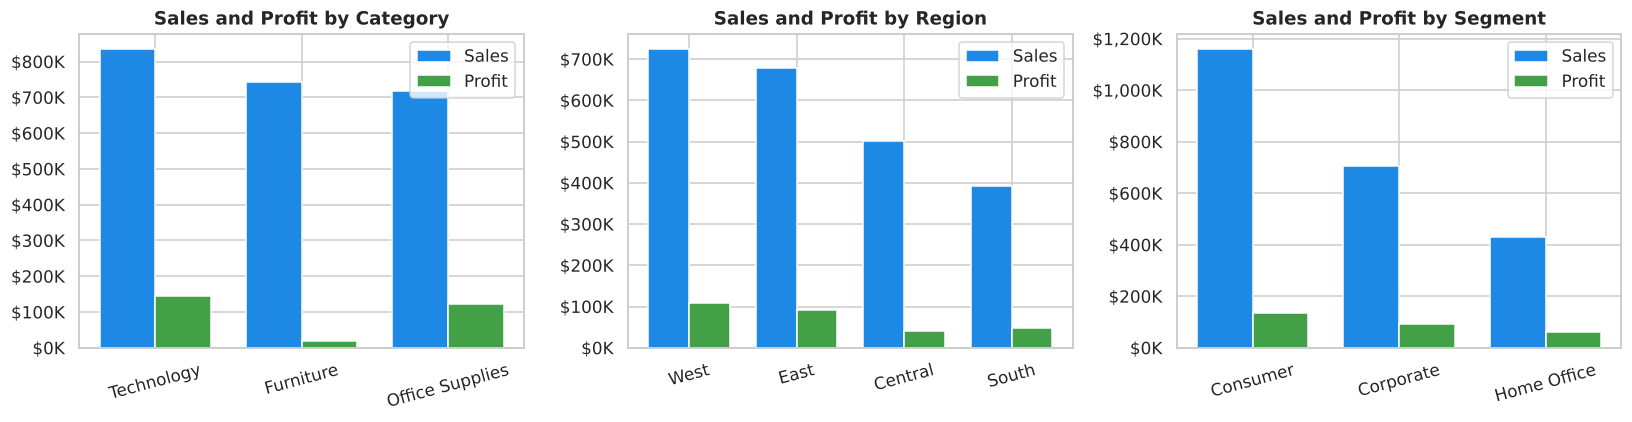

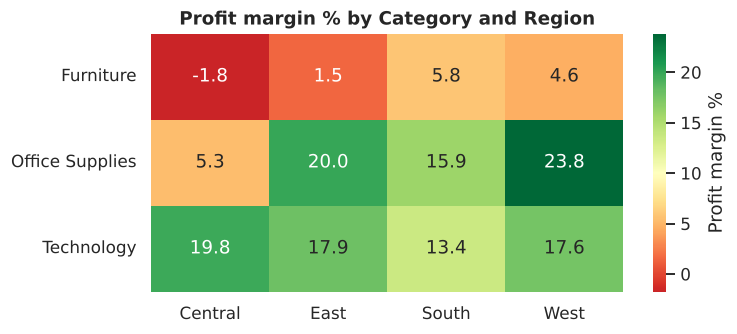

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, dim in zip(axes, ["Category", "Region", "Segment"]):
    g = summarise(dim)
    x = np.arange(len(g)); w = 0.38
    ax.bar(x - w/2, g["Sales"], w, label="Sales", color="#1E88E5")
    ax.bar(x + w/2, g["Profit"], w, label="Profit", color="#43A047")
    ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=15)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
    ax.set_title(f"Sales and Profit by {dim}"); ax.legend()
plt.tight_layout(); plt.show()

pivot = df.pivot_table(index="Category", columns="Region", values="Profit", aggfunc="sum") / \
        df.pivot_table(index="Category", columns="Region", values="Sales", aggfunc="sum") * 100
plt.figure(figsize=(7, 3.2))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn", center=10, cbar_kws={"label": "Profit margin %"})
plt.title("Profit margin % by Category and Region"); plt.ylabel(""); plt.xlabel("")
plt.tight_layout(); plt.show()

**Reading the output.** Technology brings in the most revenue, but **Furniture is the real outlier**. It earns 32.3% of sales and only a **2.49% margin**, against about 17% for Technology and Office Supplies. By region, Central lags with a **7.92% margin** against 14.94% in the West.

## 6. Monthly sales velocity and seasonality

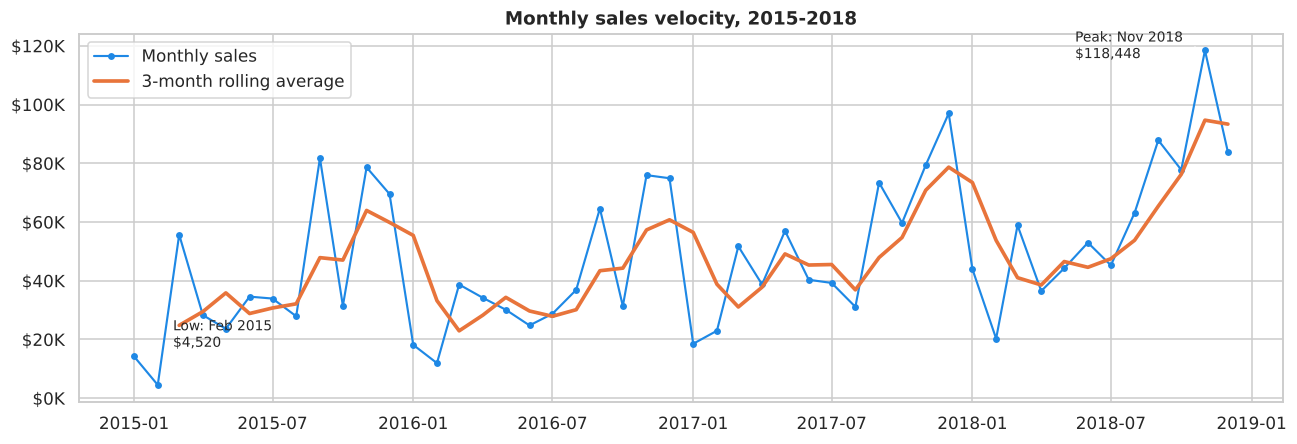

,Sales,Profit,YoY growth %,Margin %
Year,,,,
2015,"484,247.50","49,543.97",NaN,10.23
2016,"470,532.51","61,618.60",-2.83,13.10
2017,"609,205.60","81,795.17",29.47,13.43
2018,"733,215.26","93,439.27",20.36,12.74


In [10]:
monthly = df.groupby("Year-Month")["Sales"].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index, monthly.values, marker="o", ms=3.5, lw=1.4, color="#1E88E5", label="Monthly sales")
ax.plot(monthly.index, monthly.rolling(3).mean(), lw=2.4, color="#E8743B", label="3-month rolling average")
peak, trough = monthly.idxmax(), monthly.idxmin()
ax.annotate(f"Peak: {peak:%b %Y}\n${monthly.max():,.0f}", (peak, monthly.max()), xytext=(-85, -5),
            textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate(f"Low: {trough:%b %Y}\n${monthly.min():,.0f}", (trough, monthly.min()), xytext=(10, 25),
            textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
ax.set_title("Monthly sales velocity, 2015-2018"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
yearly["YoY growth %"] = yearly["Sales"].pct_change() * 100
yearly["Margin %"] = yearly["Profit"] / yearly["Sales"] * 100
yearly

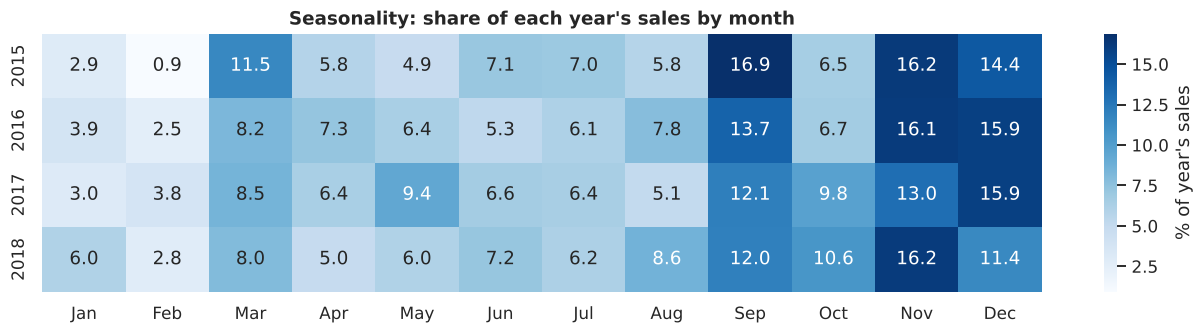

Sep-Dec share of sales: 51.6%
Nov-Dec share of sales: 29.5%
Jan-Feb share of sales: 6.7%


In [11]:
# Seasonality: each month's share of that year's sales (removes the growth trend)
share = (df.pivot_table(index="Year", columns="Month", values="Sales", aggfunc="sum")
           .pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100))
share.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.figure(figsize=(12, 3.2))
sns.heatmap(share, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of year's sales"})
plt.title("Seasonality: share of each year's sales by month"); plt.ylabel("")
plt.tight_layout(); plt.show()

avg = df.groupby("Month")["Sales"].sum() / df["Sales"].sum() * 100
print(f"Sep-Dec share of sales: {avg.loc[9:12].sum():.1f}%")
print(f"Nov-Dec share of sales: {avg.loc[[11, 12]].sum():.1f}%")
print(f"Jan-Feb share of sales: {avg.loc[[1, 2]].sum():.1f}%")

**Reading the output.** Sales are strongly seasonal and the pattern repeats every year: **September to December produce 51.6% of annual sales** (November and December alone: 29.5%), while January and February produce only 6.7%. Sales dipped 2.8% in 2016, then grew 29.5% in 2017 and 20.4% in 2018.

## 7. Category and sub-category revenue

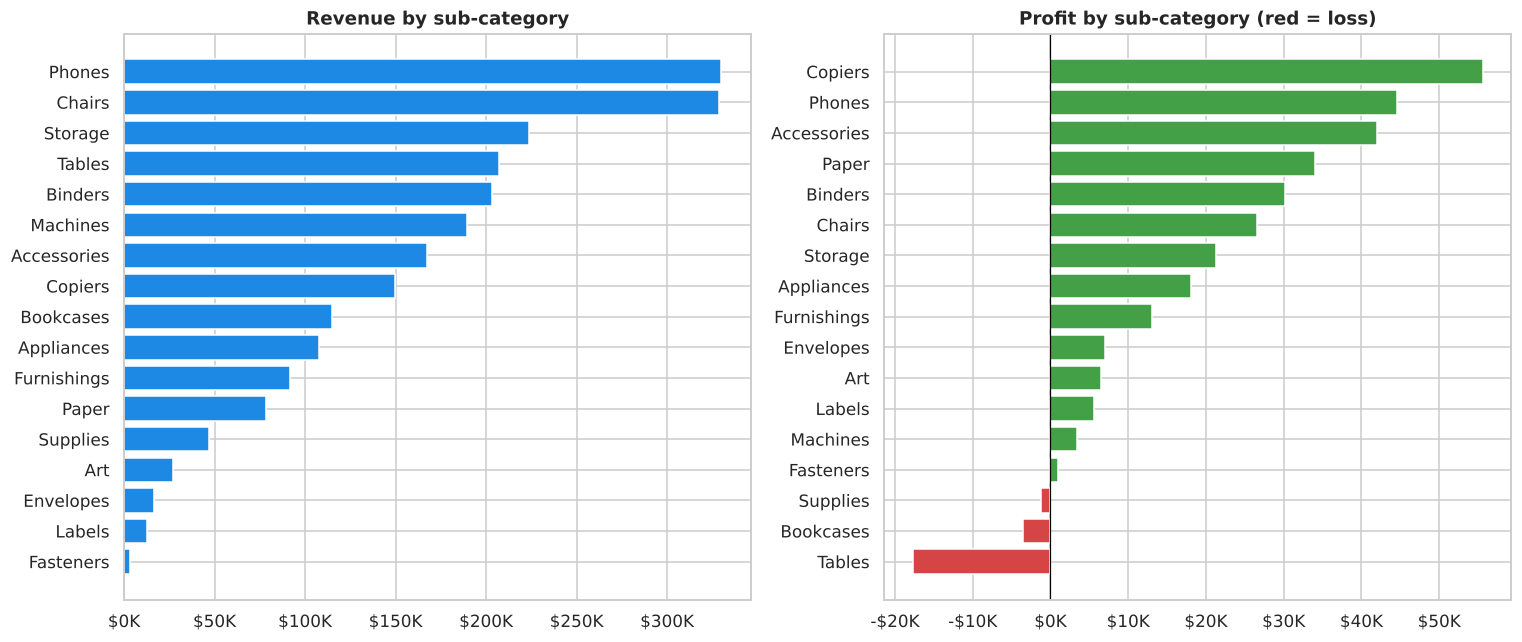

,Category,Sub-Category,Sales,Profit,Margin %
3,Furniture,Tables,"206,965.53","-17,725.48",-8.56
0,Furniture,Bookcases,"114,880.00","-3,472.56",-3.02
12,Office Supplies,Supplies,"46,673.54","-1,189.10",-2.55
8,Office Supplies,Fasteners,"3,024.28",949.52,31.40
15,Technology,Machines,"189,238.63","3,384.76",1.79


In [12]:
sub = (df.groupby(["Category", "Sub-Category"])
         .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).reset_index())
sub["Margin %"] = sub["Profit"] / sub["Sales"] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
s = sub.sort_values("Sales")
axes[0].barh(s["Sub-Category"], s["Sales"], color="#1E88E5")
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}K"))
axes[0].set_title("Revenue by sub-category")

p = sub.sort_values("Profit")
axes[1].barh(p["Sub-Category"], p["Profit"], color=np.where(p["Profit"] < 0, "#D64545", "#43A047"))
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"-${abs(v)/1000:,.0f}K" if v < 0 else f"${v/1000:,.0f}K"))
axes[1].axvline(0, color="black", lw=0.8); axes[1].set_title("Profit by sub-category (red = loss)")
plt.tight_layout(); plt.show()

sub.sort_values("Profit").head(5).round(2)

**Reading the output.** Three sub-categories lose money: **Tables (-$17,725; -8.56% margin)**, **Bookcases (-$3,473)** and **Supplies (-$1,189)**. Tables are the 4th-largest revenue line, so a large revenue stream is destroying value. Machines are barely profitable (1.79% margin).

## 8. Customer purchase volume

Customers: 793
Average orders per customer: 6.3 (median 6)
Repeat customers (2+ orders): 98.5%
Top 10% of customers (79) generate 30.6% of sales
Loss-making customers: 155 (19.5% of customers)


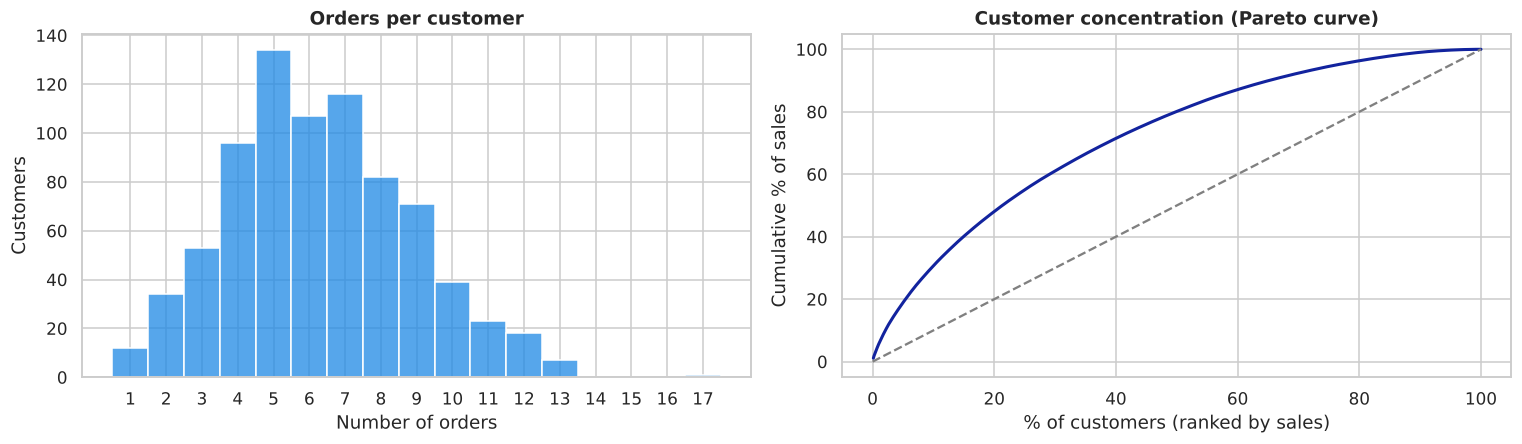

,Orders,Sales,Profit
Customer ID,,,
SM-20320,5,"25,043.05","-1,980.74"
TC-20980,5,"19,052.22","8,981.32"
RB-19360,6,"15,117.34","6,976.10"
TA-21385,4,"14,595.62","4,703.79"
AB-10105,10,"14,473.57","5,444.81"


In [13]:
cust = df.groupby("Customer ID").agg(Orders=("Order ID", "nunique"), Sales=("Sales", "sum"),
                                     Profit=("Profit", "sum")).sort_values("Sales", ascending=False)
print(f"Customers: {len(cust):,}")
print(f"Average orders per customer: {cust['Orders'].mean():.1f} (median {cust['Orders'].median():.0f})")
print(f"Repeat customers (2+ orders): {(cust['Orders'] > 1).mean() * 100:.1f}%")
top10 = cust.head(int(len(cust) * 0.10))
print(f"Top 10% of customers ({len(top10)}) generate {top10['Sales'].sum() / cust['Sales'].sum() * 100:.1f}% of sales")
print(f"Loss-making customers: {(cust['Profit'] < 0).sum()} ({(cust['Profit'] < 0).mean() * 100:.1f}% of customers)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(cust["Orders"], discrete=True, color="#1E88E5", ax=axes[0])
axes[0].set_xticks(range(1, int(cust["Orders"].max()) + 1))
axes[0].set_title("Orders per customer"); axes[0].set_xlabel("Number of orders"); axes[0].set_ylabel("Customers")

cum = cust["Sales"].cumsum() / cust["Sales"].sum() * 100
axes[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color="#12239E", lw=2)
axes[1].plot([0, 100], [0, 100], "--", color="grey")
axes[1].set_xlabel("% of customers (ranked by sales)"); axes[1].set_ylabel("Cumulative % of sales")
axes[1].set_title("Customer concentration (Pareto curve)")
plt.tight_layout(); plt.show()

cust.head(5).round(2)

**Reading the output.** Customers buy often: **98.5% are repeat customers**, averaging 6.3 orders each. Revenue is only moderately concentrated, as the top 10% of customers (79) generate **30.6% of sales**. However, **155 customers (19.5%) are net loss-making**, and the biggest customer by sales (`SM-20320`, $25,043) lost $1,981 overall.

## 9. Discount sensitivity

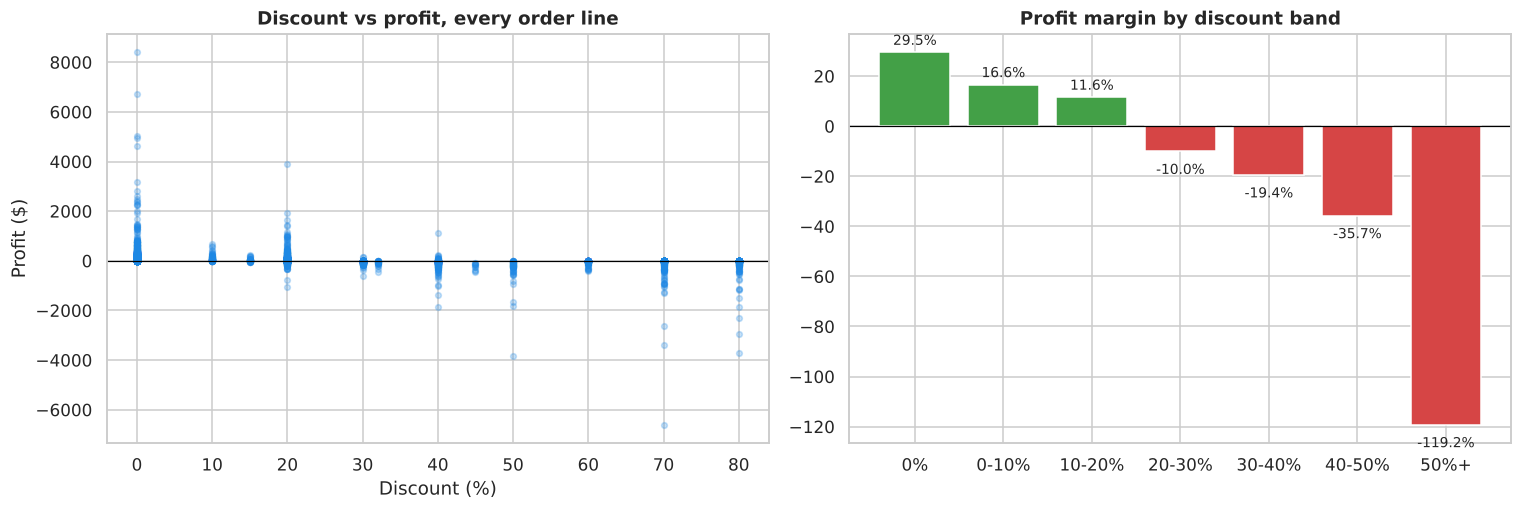

,Lines,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,"1,087,908.47","320,987.60",29.51
0-10%,94,"54,369.35","9,029.18",16.61
10-20%,3709,"792,152.89","91,756.30",11.58
20-30%,227,"103,226.66","-10,369.28",-10.05
30-40%,233,"130,911.24","-25,448.19",-19.44
40-50%,77,"64,403.51","-22,999.54",-35.71
50%+,856,"64,228.74","-76,559.05",-119.20


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(df["Discount"] * 100, df["Profit"], alpha=0.25, s=14, color="#1E88E5")
axes[0].axhline(0, color="black", lw=0.8)
axes[0].set_xlabel("Discount (%)"); axes[0].set_ylabel("Profit ($)"); axes[0].set_title("Discount vs profit, every order line")

band = df.groupby("Discount Band", observed=True).agg(Lines=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
band["Margin %"] = band["Profit"] / band["Sales"] * 100
axes[1].bar(band.index.astype(str), band["Margin %"], color=np.where(band["Margin %"] < 0, "#D64545", "#43A047"))
for i, v in enumerate(band["Margin %"]):
    axes[1].text(i, v + (3 if v >= 0 else -9), f"{v:.1f}%", ha="center", fontsize=9)
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_title("Profit margin by discount band")
plt.tight_layout(); plt.show()
band.round(2)

In [15]:
high = df[df["Discount"] > 0.20]
low = df[df["Discount"] <= 0.20]
print(f"Lines with discount above 20%: {len(high):,} ({len(high) / len(df) * 100:.1f}% of lines)")
print(f"  loss-making: {(high['Profit'] < 0).mean() * 100:.1f}%")
print(f"Lines with discount of 20% or less: {len(low):,}")
print(f"  loss-making: {(low['Profit'] < 0).mean() * 100:.1f}%")
print(f"Correlation, discount vs profit margin: {df['Discount'].corr(df['Profit Margin']):.2f}")
print(f"Total losses on loss-making lines: -${abs(df.loc[df['Profit'] < 0, 'Profit'].sum()):,.0f}")

tables = (df[df["Sub-Category"] == "Tables"].groupby("Discount Band", observed=True)["Profit"].sum().round(0))
print("\nTables: profit by discount band")
tables[tables != 0]

Lines with discount above 20%: 1,393 (13.9% of lines)
  loss-making: 96.8%
Lines with discount of 20% or less: 8,601
  loss-making: 6.1%
Correlation, discount vs profit margin: -0.86
Total losses on loss-making lines: -$156,131

Tables: profit by discount band


Discount Band
0%        13,276.00
10-20%      -304.00
20-30%    -3,402.00
30-40%   -16,187.00
40-50%   -11,108.00
Name: Profit, dtype: float64

**Reading the output.** Discount is the clearest profit driver in the data. Up to 20% discount, products stay profitable overall, and only 6.1% of order lines lose money. **Above 20%, 96.8% of lines lose money**, and margins fall from -10% (20-30%) to -119% (50%+). The correlation between discount and profit margin is **-0.86**. Tables show the effect clearly: they earn $13,276 profit at no discount and lose $16,187 at 30-40%.

## 10. Regional deep dive: why does Central lag?

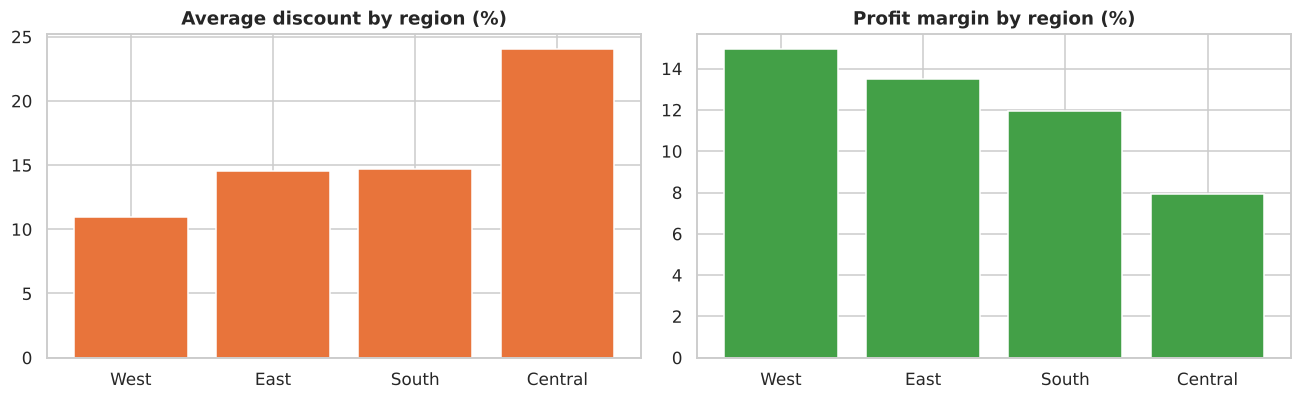

,Sales,Profit,AvgDiscount,Margin %
Region,,,,
West,"725,457.82","108,418.45",10.93,14.94
East,"678,781.24","91,522.78",14.54,13.48
South,"391,721.90","46,749.43",14.73,11.93
Central,"501,239.89","39,706.36",24.04,7.92


Five least profitable states:


,Sales,Profit
State,,
Texas,"170,188.00","-25,729.00"
Ohio,"78,258.00","-16,971.00"
Pennsylvania,"116,512.00","-15,560.00"
Illinois,"80,166.00","-12,608.00"
North Carolina,"55,603.00","-7,491.00"


In [16]:
reg = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), AvgDiscount=("Discount", "mean"))
reg["Margin %"] = reg["Profit"] / reg["Sales"] * 100
reg["AvgDiscount"] *= 100
reg = reg.sort_values("Margin %", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(reg.index, reg["AvgDiscount"], color="#E8743B"); axes[0].set_title("Average discount by region (%)")
axes[1].bar(reg.index, reg["Margin %"], color="#43A047"); axes[1].set_title("Profit margin by region (%)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()
display(reg.round(2))

state = df.groupby("State").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Profit")
print("Five least profitable states:")
state.head(5).round(0)

**Reading the output.** Central gives the deepest discounts (**24.0% on average**, against 10.9% in the West) and has the lowest margin (7.92%). The least profitable states are **Texas (-$25.7K), Ohio (-$17.0K), Pennsylvania (-$15.6K) and Illinois (-$12.6K)**. Regional margins track discounting, which links this finding to the discount analysis above.

## 11. Executive takeaways

| # | Takeaway | Evidence | Recommended action |
|---|---|---|---|
| 1 | **Discounts above 20% almost always lose money.** | 96.8% of lines with discounts above 20% are loss-making (6.1% at 20% or below). Margin is -10% at 20-30% and -119% at 50%+. | Cap discounts at 20% unless approved, and review the 1,393 deeply discounted lines. |
| 2 | **Furniture drives revenue but not profit.** | 32.3% of sales, 2.49% margin, against about 17% for Technology and Office Supplies. Tables lose $17,725 (-8.56%) and Bookcases lose $3,473. | Reprice or restrict discounting on Tables and Bookcases. |
| 3 | **Sales are highly seasonal, peaking in Q4.** | September to December earn 51.6% of annual sales (November and December 29.5%), against 6.7% for January and February. | Build inventory and staffing plans around Q4, and run demand-building promotions in the slow months. |
| 4 | **The Central region underperforms because of discounting.** | Margin of 7.92% against 14.94% in the West, with average discounts of 24.0% against 10.9%. Texas, Ohio, Pennsylvania and Illinois are loss-making. | Tighten discount rules in the Central region and the four loss-making states. |
| 5 | **Customers are loyal, but some of the biggest are unprofitable.** | 98.5% are repeat buyers (6.3 orders on average). 155 customers (19.5%) are loss-making, including the top customer by sales. | Review pricing and discount terms for large accounts, and manage customers by profit as well as revenue. |
| 6 | **Growth is strong, and margins have levelled off.** | Sales grew 51.4% from 2015 to 2018 (+29.5% in 2017, +20.4% in 2018). Margin rose from 10.2% to 13.4% by 2017, then eased to 12.7% in 2018. | Protect margin as volume grows, with discount discipline as the main lever. |

**Overall.** The business is growing, but its profit is held back by a small number of controllable issues: deep discounts, the Furniture sub-categories and Central region pricing. Fixing these would improve profit without needing more sales.

### Limitations
- The data has no cost or budget fields, so profit is taken as given and margins cannot be broken down further.
- Results are associations in historical data. Discount and profit are strongly linked, but a controlled price test would be needed to prove cause and effect.
- The Returns list (296 distinct returned orders) was removed with the other non-order rows and is not reflected in sales or profit. Returns are included in all figures, as the dataset records them.